<a href="https://colab.research.google.com/github/Akanaika13/Computer-Vision_192371061/blob/main/Exp_26to30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ATLURU KANAIKA -192371061

Experiment-26

In [40]:
import cv2
from google.colab import files
from IPython.display import Video, display

uploaded = files.upload()
filename = list(uploaded.keys())[0]

cap = cv2.VideoCapture(filename)
frames = []

while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)

cap.release()

if len(frames) == 0:
    print("Video not found")
else:
    h, w = frames[0].shape[:2]

    out = cv2.VideoWriter('/content/reverse.mp4',
        cv2.VideoWriter_fourcc(*'mp4v'), 20, (w,h))

    for frame in frames[::-1]:
        out.write(frame)

    out.release()

    print("Original Video")
    display(Video(filename, embed=True))

    print("Reverse Video")
    display(Video('/content/reverse.mp4', embed=True))

Saving WhatsApp Video 2026-11-26 at 13.22.15.mp4 to WhatsApp Video 2026-11-26 at 13.22.15 (1).mp4
Original Video


Reverse Video


Experiment-27

In [1]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install opencv-contrib-python-headless==4.10.0.84

Found existing installation: opencv-contrib-python-headless 4.10.0.84
Uninstalling opencv-contrib-python-headless-4.10.0.84:
  Successfully uninstalled opencv-contrib-python-headless-4.10.0.84
  Using cached opencv_contrib_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_contrib_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (56.0 MB)


In [2]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, 'CascadeClassifier'))
print("DNN:", hasattr(cv2.dnn, 'readNetFromCaffe'))

OpenCV Version: 4.10.0
CascadeClassifier: True
DNN: True


Saving face.jpg to face (4).jpg
Original Image


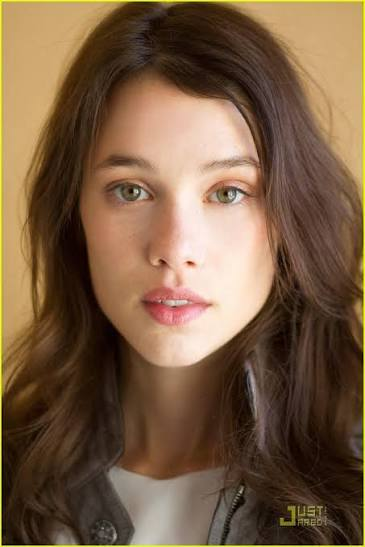

Face Detection Output


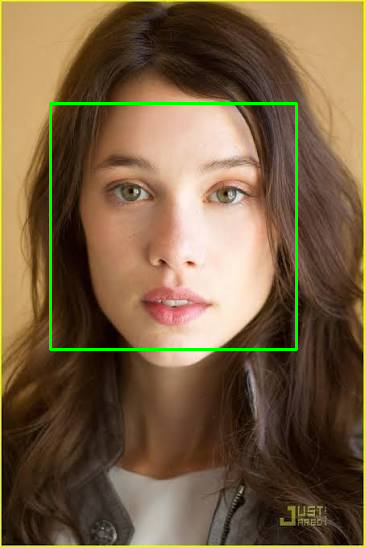

Number of Faces: 1


In [3]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename)
original = img.copy()

# Load face detector
face = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    'haarcascade_frontalface_default.xml'
)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face.detectMultiScale(gray, 1.3, 5)

# Draw rectangles
for (x,y,w,h) in faces:
    cv2.rectangle(img, (x,y), (x+w,y+h),
                  (0,255,0), 2)

print("Original Image")
cv2_imshow(original)

print("Face Detection Output")
cv2_imshow(img)

print("Number of Faces:", len(faces))

Experiment-28

Saving vehicle.jpg to vehicle.jpg


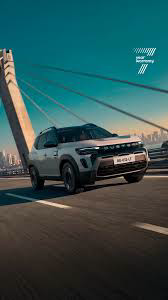

In [4]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

!wget -q https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names -O coco.names
!wget -q https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3-tiny.cfg -O yolov3-tiny.cfg
!wget -q https://pjreddie.com/media/files/yolov3-tiny.weights -O yolov3-tiny.weights

net = cv2.dnn.readNet('yolov3-tiny.weights', 'yolov3-tiny.cfg')

with open('coco.names') as f:
    classes = f.read().strip().split('\n')

uploaded = files.upload()
filename = list(uploaded.keys())[0]

cap = cv2.VideoCapture(filename)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    blob = cv2.dnn.blobFromImage(frame, 1/255, (416,416),
                                 swapRB=True, crop=False)
    net.setInput(blob)
    outputs = net.forward(net.getUnconnectedOutLayersNames())

    for output in outputs:
        for detection in output:
            scores = detection[5:]
            class_id = scores.argmax()
            confidence = scores[class_id]

            if classes[class_id] in ['car','bus','truck','motorbike'] and confidence > 0.5:
                h, w = frame.shape[:2]
                bw = int(detection[2]*w)
                bh = int(detection[3]*h)
                x = int(detection[0]*w-bw/2)
                y = int(detection[1]*h-bh/2)

                cv2.rectangle(frame, (x,y), (x+bw,y+bh), (0,255,0), 2)
                cv2.putText(frame, classes[class_id], (x,y-5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

    cv2_imshow(frame)

cap.release()

Experiment-29

Saving smile.jpg to smile.jpg
Original Image


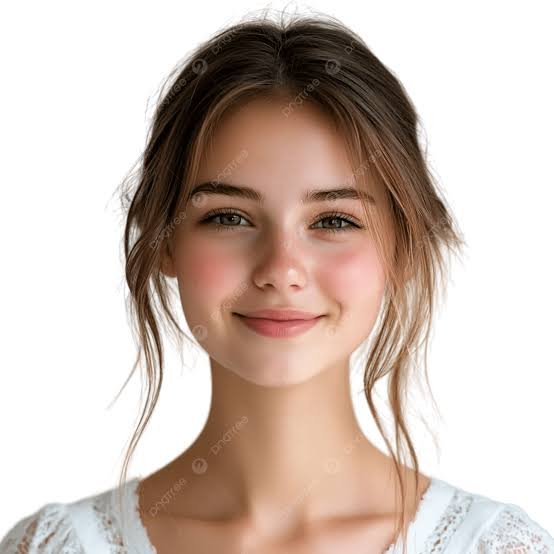

Eye Detection Output


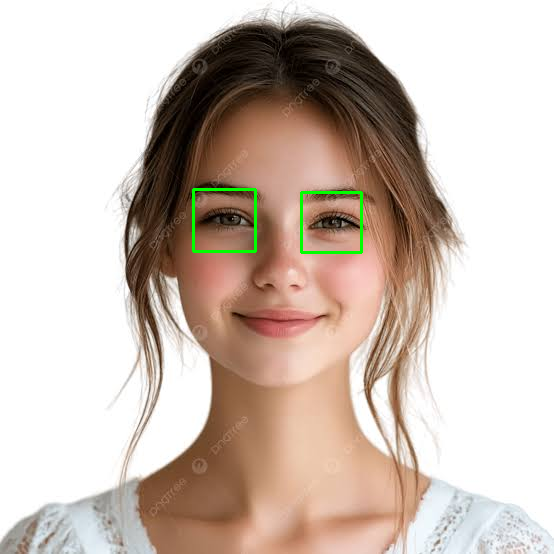

In [7]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()
img = cv2.imread(list(uploaded.keys())[0])

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

eye = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye.xml')

eyes = eye.detectMultiScale(gray, 1.3, 5)

for (x,y,w,h) in eyes:
    cv2.rectangle(img, (x,y), (x+w,y+h), (0,255,0), 2)

print("Original Image")
cv2_imshow(cv2.imread(list(uploaded.keys())[0]))

print("Eye Detection Output")
cv2_imshow(img)

Experiment-30

Saving smile.jpg to smile (1).jpg
Original Image


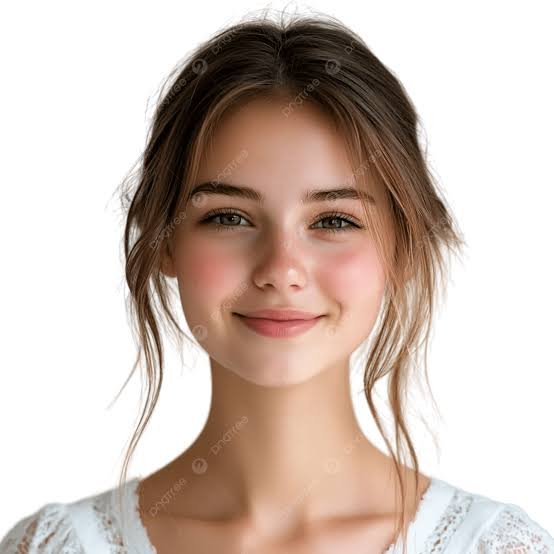

Smile Detection Output


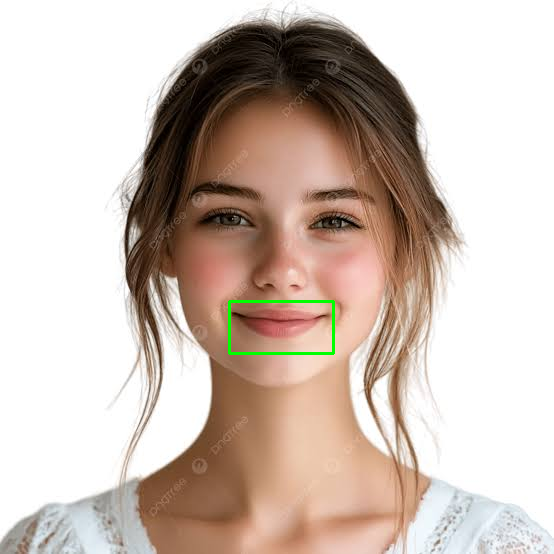

In [8]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()
img = cv2.imread(list(uploaded.keys())[0])

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

smile = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_smile.xml')

smiles = smile.detectMultiScale(gray, 1.7, 20)

for (x,y,w,h) in smiles:
    cv2.rectangle(img, (x,y), (x+w,y+h), (0,255,0), 2)

print("Original Image")
cv2_imshow(cv2.imread(list(uploaded.keys())[0]))

print("Smile Detection Output")
cv2_imshow(img)

Atluru Kanaika-192371061